Factory Reference Analysis
Factory master table

In [2]:
#Factory master table
# Create and validate the factory master table

import os
import hashlib
import pandas as pd
import numpy as np

PROJECT_ROOT = r"C:\Users\hp\Nassau_Candy_Final_Submission"
RAW_FILE = os.path.join(PROJECT_ROOT, "data", "raw", "Nassau Candy Distributor.csv")
PROCESSED_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
FIGURES_DIR = os.path.join(PROJECT_ROOT, "reports", "figures")

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

def calculate_sha256(file_path):
    sha256 = hashlib.sha256()
    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)
    return sha256.hexdigest()

assert os.path.exists(RAW_FILE), "Original CSV file not found."

original_sha256_before = calculate_sha256(RAW_FILE)
df_original = pd.read_csv(RAW_FILE)

factory_master = pd.DataFrame([
    {"Factory_ID": "F01", "Factory_Name": "Lot's O' Nuts"},
    {"Factory_ID": "F02", "Factory_Name": "Wicked Choccy's"},
    {"Factory_ID": "F03", "Factory_Name": "Sugar Shack"},
    {"Factory_ID": "F04", "Factory_Name": "Secret Factory"},
    {"Factory_ID": "F05", "Factory_Name": "The Other Factory"}
])

FACTORY_MASTER_FILE = os.path.join(PROCESSED_DIR, "factory_master.csv")
factory_master.to_csv(FACTORY_MASTER_FILE, index=False)

display(factory_master)

print("Factory count:", len(factory_master))
print("Unique factory IDs:", factory_master["Factory_ID"].nunique())
print("Unique factory names:", factory_master["Factory_Name"].nunique())
print("Output file exists:", os.path.exists(FACTORY_MASTER_FILE))

assert len(factory_master) == 5
assert factory_master["Factory_ID"].is_unique
assert factory_master["Factory_Name"].is_unique

print("\nSUCCESS: Factory master table created.")

,Factory_ID,Factory_Name
0,F01,Lot's O' Nuts
1,F02,Wicked Choccy's
2,F03,Sugar Shack
3,F04,Secret Factory
4,F05,The Other Factory


Factory count: 5
Unique factory IDs: 5
Unique factory names: 5
Output file exists: True

SUCCESS: Factory master table created.


In [4]:
#Factory coordinates table
# Create and validate the factory coordinates table

factory_coordinates = pd.DataFrame([
    {"Factory_Name": "Lot's O' Nuts", "Latitude": 32.881893, "Longitude": -111.768036},
    {"Factory_Name": "Wicked Choccy's", "Latitude": 32.076176, "Longitude": -81.088371},
    {"Factory_Name": "Sugar Shack", "Latitude": 48.119140, "Longitude": -96.181150},
    {"Factory_Name": "Secret Factory", "Latitude": 41.446333, "Longitude": -90.565487},
    {"Factory_Name": "The Other Factory", "Latitude": 35.117500, "Longitude": -89.971107}
])

FACTORY_COORDINATES_FILE = os.path.join(
    PROCESSED_DIR, "factory_coordinates.csv"
)

factory_coordinates.to_csv(FACTORY_COORDINATES_FILE, index=False)

display(factory_coordinates)

print("Coordinate records:", len(factory_coordinates))
print("Missing coordinates:", factory_coordinates.isna().sum().sum())
print("Unique factories:", factory_coordinates["Factory_Name"].nunique())

assert len(factory_coordinates) == 5
assert factory_coordinates[["Latitude", "Longitude"]].notna().all().all()
assert factory_coordinates["Factory_Name"].is_unique
assert set(factory_coordinates["Factory_Name"]) == set(factory_master["Factory_Name"])

print("\nSUCCESS: Factory coordinates table created.")

,Factory_Name,Latitude,Longitude
0,Lot's O' Nuts,32.881893,-111.768036
1,Wicked Choccy's,32.076176,-81.088371
2,Sugar Shack,48.119140,-96.181150
3,Secret Factory,41.446333,-90.565487
4,The Other Factory,35.117500,-89.971107


Coordinate records: 5
Missing coordinates: 0
Unique factories: 5

SUCCESS: Factory coordinates table created.


In [6]:
#Product-factory mapping table
# Create the exact product-to-factory reference mapping

product_factory_mapping = pd.DataFrame([
    {"Product Name": "Wonka Bar - Nutty Crunch Surprise", "Mapped Factory": "Lot's O' Nuts", "Reference Division": "Chocolate"},
    {"Product Name": "Wonka Bar - Fudge Mallows", "Mapped Factory": "Lot's O' Nuts", "Reference Division": "Chocolate"},
    {"Product Name": "Wonka Bar -Scrumdiddlyumptious", "Mapped Factory": "Lot's O' Nuts", "Reference Division": "Chocolate"},
    {"Product Name": "Wonka Bar - Milk Chocolate", "Mapped Factory": "Wicked Choccy's", "Reference Division": "Chocolate"},
    {"Product Name": "Wonka Bar - Triple Dazzle Caramel", "Mapped Factory": "Wicked Choccy's", "Reference Division": "Chocolate"},
    {"Product Name": "Laffy Taffy", "Mapped Factory": "Sugar Shack", "Reference Division": "Sugar"},
    {"Product Name": "SweeTARTS", "Mapped Factory": "Sugar Shack", "Reference Division": "Sugar"},
    {"Product Name": "Nerds", "Mapped Factory": "Sugar Shack", "Reference Division": "Sugar"},
    {"Product Name": "Fun Dip", "Mapped Factory": "Sugar Shack", "Reference Division": "Sugar"},
    {"Product Name": "Everlasting Gobstopper", "Mapped Factory": "Secret Factory", "Reference Division": "Sugar"},
    {"Product Name": "Hair Toffee", "Mapped Factory": "The Other Factory", "Reference Division": "Sugar"},
    {"Product Name": "Fizzy Lifting Drinks", "Mapped Factory": "Sugar Shack", "Reference Division": "Sugar"},
    {"Product Name": "Lickable Wallpaper", "Mapped Factory": "Secret Factory", "Reference Division": "Other"},
    {"Product Name": "Wonka Gum", "Mapped Factory": "Secret Factory", "Reference Division": "Other"},
    {"Product Name": "Kazookles", "Mapped Factory": "The Other Factory", "Reference Division": "Other"}
])

PRODUCT_MAPPING_FILE = os.path.join(
    PROCESSED_DIR, "product_factory_mapping.csv"
)

product_factory_mapping.to_csv(PRODUCT_MAPPING_FILE, index=False)

display(product_factory_mapping)

print("Mapping records:", len(product_factory_mapping))
print("Unique mapped products:", product_factory_mapping["Product Name"].nunique())
print("Unique mapped factories:", product_factory_mapping["Mapped Factory"].nunique())
print("Missing mapping values:", product_factory_mapping.isna().sum().sum())

assert len(product_factory_mapping) == 15
assert product_factory_mapping["Product Name"].is_unique
assert set(product_factory_mapping["Mapped Factory"]).issubset(
    set(factory_master["Factory_Name"])
)

print("\nSUCCESS: Product-factory mapping table created.")

,Product Name,Mapped Factory,Reference Division
0,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Chocolate
1,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Chocolate
2,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Chocolate
3,Wonka Bar - Milk Chocolate,Wicked Choccy's,Chocolate
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Chocolate
5,Laffy Taffy,Sugar Shack,Sugar
6,SweeTARTS,Sugar Shack,Sugar
7,Nerds,Sugar Shack,Sugar
8,Fun Dip,Sugar Shack,Sugar
9,Everlasting Gobstopper,Secret Factory,Sugar


Mapping records: 15
Unique mapped products: 15
Unique mapped factories: 5
Missing mapping values: 0

SUCCESS: Product-factory mapping table created.


In [8]:
#Verify product names
# Objective: Compare mapping product names against the original CSV using exact matching. No spelling corrections or fuzzy matching.
# Verify exact product-name matching against the original CSV

csv_products = set(df_original["Product Name"].dropna().unique())
mapped_products = set(product_factory_mapping["Product Name"].dropna().unique())

product_name_verification = product_factory_mapping[
    ["Product Name", "Mapped Factory"]
].copy()

product_name_verification["Exact Match in CSV"] = (
    product_name_verification["Product Name"].isin(csv_products)
)

product_name_verification["Verification Status"] = np.where(
    product_name_verification["Exact Match in CSV"],
    "PASS",
    "NOT FOUND"
)

PRODUCT_VERIFICATION_FILE = os.path.join(
    PROCESSED_DIR, "factory_product_name_verification.csv"
)

product_name_verification.to_csv(
    PRODUCT_VERIFICATION_FILE, index=False
)

display(product_name_verification)

print("Mapped products:", len(mapped_products))
print("Products found exactly:", product_name_verification["Exact Match in CSV"].sum())
print("Products not found:", (~product_name_verification["Exact Match in CSV"]).sum())

print("\nProducts in CSV but absent from mapping:")
print(sorted(csv_products - mapped_products))

assert len(product_name_verification) == 15

print("\nSUCCESS: Exact product-name verification completed.")

,Product Name,Mapped Factory,Exact Match in CSV,Verification Status
0,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,True,PASS
1,Wonka Bar - Fudge Mallows,Lot's O' Nuts,True,PASS
2,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,True,PASS
3,Wonka Bar - Milk Chocolate,Wicked Choccy's,True,PASS
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,True,PASS
5,Laffy Taffy,Sugar Shack,True,PASS
6,SweeTARTS,Sugar Shack,True,PASS
7,Nerds,Sugar Shack,True,PASS
8,Fun Dip,Sugar Shack,True,PASS
9,Everlasting Gobstopper,Secret Factory,True,PASS


Mapped products: 15
Products found exactly: 15
Products not found: 0

Products in CSV but absent from mapping:
[]

SUCCESS: Exact product-name verification completed.


In [10]:
#Verify mapping divisions
#Objective: Compare each mapped product's reference division with its division in the original CSV
# Verify reference divisions against original CSV divisions

csv_product_divisions = (
    df_original[["Product Name", "Division"]]
    .drop_duplicates()
    .copy()
)

division_counts = (
    csv_product_divisions.groupby("Product Name")["Division"]
    .nunique()
)

division_check = product_factory_mapping.merge(
    csv_product_divisions,
    on="Product Name",
    how="left",
    validate="one_to_many"
)

division_check["CSV Division Count"] = (
    division_check["Product Name"].map(division_counts)
)

division_check["Division Match"] = (
    division_check["Reference Division"] == division_check["Division"]
)

division_check["Verification Status"] = np.select(
    [
        division_check["CSV Division Count"].isna(),
        division_check["CSV Division Count"].gt(1),
        division_check["Division Match"]
    ],
    [
        "PRODUCT NOT FOUND",
        "MULTIPLE CSV DIVISIONS",
        "PASS"
    ],
    default="DIVISION MISMATCH"
)

DIVISION_VERIFICATION_FILE = os.path.join(
    PROCESSED_DIR, "factory_division_verification.csv"
)

division_check.to_csv(DIVISION_VERIFICATION_FILE, index=False)

display(division_check)

print("\nDivision verification summary:")
print(division_check["Verification Status"].value_counts(dropna=False))

print("\nSUCCESS: Division verification report created.")

,Product Name,Mapped Factory,Reference Division,Division,CSV Division Count,Division Match,Verification Status
0,Wonka Bar - Nutty Crunch Surprise,Lot's O' Nuts,Chocolate,Chocolate,1,True,PASS
1,Wonka Bar - Fudge Mallows,Lot's O' Nuts,Chocolate,Chocolate,1,True,PASS
2,Wonka Bar -Scrumdiddlyumptious,Lot's O' Nuts,Chocolate,Chocolate,1,True,PASS
3,Wonka Bar - Milk Chocolate,Wicked Choccy's,Chocolate,Chocolate,1,True,PASS
4,Wonka Bar - Triple Dazzle Caramel,Wicked Choccy's,Chocolate,Chocolate,1,True,PASS
5,Laffy Taffy,Sugar Shack,Sugar,Sugar,1,True,PASS
6,SweeTARTS,Sugar Shack,Sugar,Sugar,1,True,PASS
7,Nerds,Sugar Shack,Sugar,Sugar,1,True,PASS
8,Fun Dip,Sugar Shack,Sugar,Sugar,1,True,PASS
9,Everlasting Gobstopper,Secret Factory,Sugar,Sugar,1,True,PASS



Division verification summary:
Verification Status
PASS    15
Name: count, dtype: int64

SUCCESS: Division verification report created.


In [12]:
#Join mapping with CSV
#Objective: Add factory reference information to a separate copy of the original dataset.
# Join factory reference mapping with a separate copy of the original dataset

df_factory_mapped = df_original.merge(
    product_factory_mapping,
    on="Product Name",
    how="left",
    validate="many_to_one",
    indicator=True
)

df_factory_mapped["Mapping Status"] = np.where(
    df_factory_mapped["_merge"] == "both",
    "Mapped",
    "Unmapped"
)

df_factory_mapped.drop(columns=["_merge"], inplace=True)

FACTORY_MAPPED_FILE = os.path.join(
    PROCESSED_DIR,
    "Nassau_Candy_Factory_Mapped_Reference.csv"
)

df_factory_mapped.to_csv(FACTORY_MAPPED_FILE, index=False)

print("Original dataset shape:", df_original.shape)
print("Factory-mapped dataset shape:", df_factory_mapped.shape)
print("Original columns retained:",
      all(col in df_factory_mapped.columns for col in df_original.columns))
print("Original row count preserved:",
      len(df_factory_mapped) == len(df_original))
print("Mapped rows:", (df_factory_mapped["Mapping Status"] == "Mapped").sum())
print("Unmapped rows:", (df_factory_mapped["Mapping Status"] == "Unmapped").sum())
print("Output file exists:", os.path.exists(FACTORY_MAPPED_FILE))

assert len(df_factory_mapped) == len(df_original)
assert all(col in df_factory_mapped.columns for col in df_original.columns)

print("\nSUCCESS: Separate factory-mapped dataset created.")

Original dataset shape: (10194, 18)
Factory-mapped dataset shape: (10194, 21)
Original columns retained: True
Original row count preserved: True
Mapped rows: 10194
Unmapped rows: 0
Output file exists: True

SUCCESS: Separate factory-mapped dataset created.


In [14]:
#Check unmapped products
#Objective: Identify any original CSV products that do not have an exact factory mapping.
# Identify products and rows without an exact factory mapping

unmapped_products = (
    df_factory_mapped.loc[
        df_factory_mapped["Mapping Status"] == "Unmapped",
        ["Product Name"]
    ]
    .value_counts()
    .reset_index(name="CSV Row Count")
)

UNMAPPED_PRODUCTS_FILE = os.path.join(
    PROCESSED_DIR, "factory_unmapped_products.csv"
)

unmapped_products.to_csv(UNMAPPED_PRODUCTS_FILE, index=False)

print("Unmapped product count:", len(unmapped_products))
print("Unmapped CSV rows:",
      (df_factory_mapped["Mapping Status"] == "Unmapped").sum())

if unmapped_products.empty:
    print("\nAll CSV products have an exact mapping.")
else:
    display(unmapped_products)

print("\nSUCCESS: Unmapped product check completed.")

Unmapped product count: 0
Unmapped CSV rows: 0

All CSV products have an exact mapping.

SUCCESS: Unmapped product check completed.


In [16]:
# Count mapped order lines
# Objective: Measure mapping coverage using CSV rows as order lines. Also report distinct orders separately.
# Calculate factory mapping coverage at order-line and order levels

total_order_lines = len(df_factory_mapped)

mapped_order_lines = (
    df_factory_mapped["Mapping Status"] == "Mapped"
).sum()

unmapped_order_lines = (
    df_factory_mapped["Mapping Status"] == "Unmapped"
).sum()

total_orders = df_factory_mapped["Order ID"].nunique()

mapped_orders = df_factory_mapped.loc[
    df_factory_mapped["Mapping Status"] == "Mapped",
    "Order ID"
].nunique()

coverage_percentage = (
    mapped_order_lines / total_order_lines * 100
    if total_order_lines > 0 else np.nan
)

mapping_coverage = pd.DataFrame([{
    "Total CSV Order Lines": total_order_lines,
    "Mapped Order Lines": mapped_order_lines,
    "Unmapped Order Lines": unmapped_order_lines,
    "Order-Line Mapping Coverage (%)": coverage_percentage,
    "Total Distinct Orders": total_orders,
    "Orders With At Least One Mapped Line": mapped_orders
}])

MAPPING_COVERAGE_FILE = os.path.join(
    PROCESSED_DIR, "factory_mapping_coverage.csv"
)

mapping_coverage.to_csv(MAPPING_COVERAGE_FILE, index=False)

display(mapping_coverage)

assert mapped_order_lines + unmapped_order_lines == total_order_lines

print("\nSUCCESS: Factory mapping coverage calculated.")

,Total CSV Order Lines,Mapped Order Lines,Unmapped Order Lines,Order-Line Mapping Coverage (%),Total Distinct Orders,Orders With At Least One Mapped Line
0,10194,10194,0,100.0,8549,8549



SUCCESS: Factory mapping coverage calculated.


In [18]:
# Factory-wise product count
# Objective: Count the number of distinct reference-mapped products assigned to each factory.
# Calculate distinct mapped product counts by factory

factory_product_count = (
    product_factory_mapping.groupby("Mapped Factory")["Product Name"]
    .nunique()
    .reindex(factory_master["Factory_Name"], fill_value=0)
    .rename("Distinct Product Count")
    .reset_index()
    .rename(columns={"index": "Factory Name"})
)

factory_product_count.rename(
    columns={"Factory_Name": "Factory Name"},
    inplace=True
)

FACTORY_PRODUCT_COUNT_FILE = os.path.join(
    PROCESSED_DIR, "factory_product_count.csv"
)

factory_product_count.to_csv(FACTORY_PRODUCT_COUNT_FILE, index=False)

display(factory_product_count)

print("Total mapped products:",
      factory_product_count["Distinct Product Count"].sum())

assert factory_product_count["Distinct Product Count"].sum() == 15

print("\nSUCCESS: Factory-wise product count created.")

,Factory Name,Distinct Product Count
0,Lot's O' Nuts,3
1,Wicked Choccy's,2
2,Sugar Shack,5
3,Secret Factory,3
4,The Other Factory,2


Total mapped products: 15

SUCCESS: Factory-wise product count created.


In [20]:
# Factory-wise sales
# Objective: Aggregate CSV sales for products assigned to each factory by the reference mapping.
# Calculate sales attributed to each factory reference portfolio

factory_sales = (
    df_factory_mapped[df_factory_mapped["Mapping Status"] == "Mapped"]
    .groupby("Mapped Factory")["Sales"]
    .sum()
    .reindex(factory_master["Factory_Name"], fill_value=0)
    .rename("Mapped Portfolio Sales")
    .reset_index()
    .rename(columns={"Mapped Factory": "Factory Name"})
)

FACTORY_SALES_FILE = os.path.join(PROCESSED_DIR, "factory_sales.csv")
factory_sales.to_csv(FACTORY_SALES_FILE, index=False)

display(factory_sales)

print("Total mapped portfolio sales:",
      factory_sales["Mapped Portfolio Sales"].sum())

print("\nSUCCESS: Factory-wise mapped portfolio sales calculated.")

,Factory_Name,Mapped Portfolio Sales
0,Lot's O' Nuts,76340.15
1,Wicked Choccy's,55352.75
2,Sugar Shack,220.98
3,Secret Factory,8587.50
4,The Other Factory,1282.25


Total mapped portfolio sales: 141783.63000000003

SUCCESS: Factory-wise mapped portfolio sales calculated.


In [22]:
# Factory-wise gross profit
# Objective: Aggregate gross profit for products assigned to each factory by the reference mapping.
# Calculate gross profit attributed to each factory reference portfolio

factory_gross_profit = (
    df_factory_mapped[df_factory_mapped["Mapping Status"] == "Mapped"]
    .groupby("Mapped Factory")["Gross Profit"]
    .sum()
    .reindex(factory_master["Factory_Name"], fill_value=0)
    .rename("Mapped Portfolio Gross Profit")
    .reset_index()
    .rename(columns={"Mapped Factory": "Factory Name"})
)

FACTORY_GROSS_PROFIT_FILE = os.path.join(
    PROCESSED_DIR, "factory_gross_profit.csv"
)

factory_gross_profit.to_csv(FACTORY_GROSS_PROFIT_FILE, index=False)

display(factory_gross_profit)

print("Total mapped portfolio gross profit:",
      factory_gross_profit["Mapped Portfolio Gross Profit"].sum())

print("\nSUCCESS: Factory-wise mapped portfolio gross profit calculated.")

,Factory_Name,Mapped Portfolio Gross Profit
0,Lot's O' Nuts,52771.05
1,Wicked Choccy's,36053.57
2,Sugar Shack,121.23
3,Secret Factory,4344.70
4,The Other Factory,152.25


Total mapped portfolio gross profit: 93442.79999999999

SUCCESS: Factory-wise mapped portfolio gross profit calculated.


In [24]:
#Factory-wise units
#Objective: Aggregate units for products assigned to each factory by the reference mapping.
# Calculate units attributed to each factory reference portfolio

factory_units = (
    df_factory_mapped[df_factory_mapped["Mapping Status"] == "Mapped"]
    .groupby("Mapped Factory")["Units"]
    .sum()
    .reindex(factory_master["Factory_Name"], fill_value=0)
    .rename("Mapped Portfolio Units")
    .reset_index()
    .rename(columns={"Mapped Factory": "Factory Name"})
)

FACTORY_UNITS_FILE = os.path.join(PROCESSED_DIR, "factory_units.csv")
factory_units.to_csv(FACTORY_UNITS_FILE, index=False)

display(factory_units)

print("Total mapped portfolio units:",
      factory_units["Mapped Portfolio Units"].sum())

print("\nSUCCESS: Factory-wise mapped portfolio units calculated.")

,Factory_Name,Mapped Portfolio Units
0,Lot's O' Nuts,21412
1,Wicked Choccy's,15863
2,Sugar Shack,107
3,Secret Factory,884
4,The Other Factory,388


Total mapped portfolio units: 38654

SUCCESS: Factory-wise mapped portfolio units calculated.


In [26]:
#Factory-to-factory distance
#Objective: Calculate straight-line distances between the five supplied factory coordinates using the Haversine formula.
# Calculate straight-line factory distances using the Haversine formula

def haversine_distance(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0088

    lat1, lon1, lat2, lon2 = np.radians(
        [lat1, lon1, lat2, lon2]
    )

    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    a = (
        np.sin(delta_lat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(delta_lon / 2) ** 2
    )

    return 2 * earth_radius_km * np.arcsin(np.sqrt(a))

factory_names = factory_coordinates["Factory_Name"].tolist()

distance_matrix = pd.DataFrame(
    index=factory_names,
    columns=factory_names,
    dtype=float
)

for _, factory_a in factory_coordinates.iterrows():
    for _, factory_b in factory_coordinates.iterrows():
        distance_matrix.loc[
            factory_a["Factory_Name"],
            factory_b["Factory_Name"]
        ] = haversine_distance(
            factory_a["Latitude"],
            factory_a["Longitude"],
            factory_b["Latitude"],
            factory_b["Longitude"]
        )

FACTORY_DISTANCE_FILE = os.path.join(
    PROCESSED_DIR, "factory_distance_matrix_km.csv"
)

distance_matrix.to_csv(FACTORY_DISTANCE_FILE)

display(distance_matrix.round(2))

print("Matrix shape:", distance_matrix.shape)
print("Diagonal values are zero:",
      np.allclose(np.diag(distance_matrix), 0))
print("Matrix is symmetric:",
      np.allclose(distance_matrix.values, distance_matrix.values.T))

assert distance_matrix.shape == (5, 5)
assert np.allclose(np.diag(distance_matrix), 0)
assert np.allclose(distance_matrix.values, distance_matrix.values.T)

print("\nSUCCESS: Straight-line factory distance matrix created.")

,Lot's O' Nuts,Wicked Choccy's,Sugar Shack,Secret Factory,The Other Factory
Lot's O' Nuts,0.00,2869.08,2137.82,2098.59,2020.58
Wicked Choccy's,2869.08,0.00,2189.19,1339.22,889.07
Sugar Shack,2137.82,2189.19,0.00,863.72,1533.82
Secret Factory,2098.59,1339.22,863.72,0.00,705.64
The Other Factory,2020.58,889.07,1533.82,705.64,0.00


Matrix shape: (5, 5)
Diagonal values are zero: True
Matrix is symmetric: True

SUCCESS: Straight-line factory distance matrix created.


Product Count Columns: ['Factory Name', 'Distinct Product Count']
Sales Columns: ['Factory Name', 'Mapped Portfolio Sales']
Gross Profit Columns: ['Factory Name', 'Mapped Portfolio Gross Profit']
Units Columns: ['Factory Name', 'Mapped Portfolio Units']

SUCCESS: Factory column names standardized.


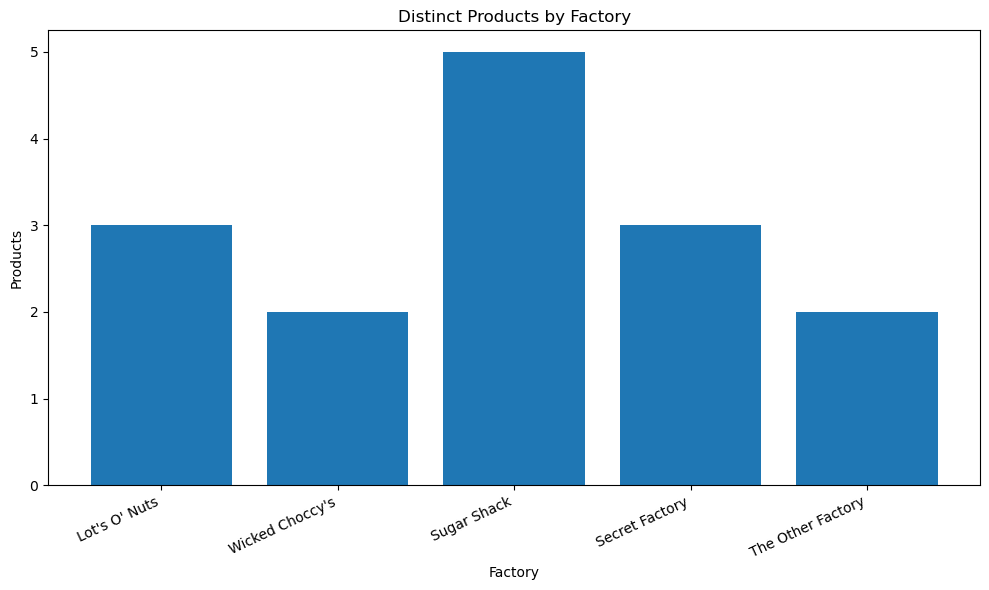

Saved: C:\Users\hp\Nassau_Candy_Final_Submission\reports\figures\factory_product_count.png


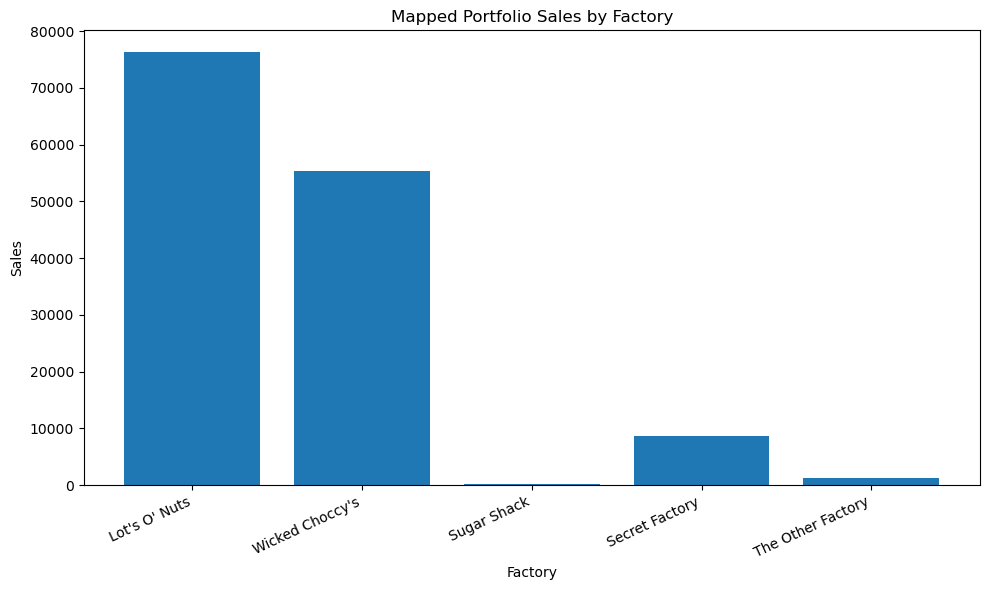

Saved: C:\Users\hp\Nassau_Candy_Final_Submission\reports\figures\factory_sales.png


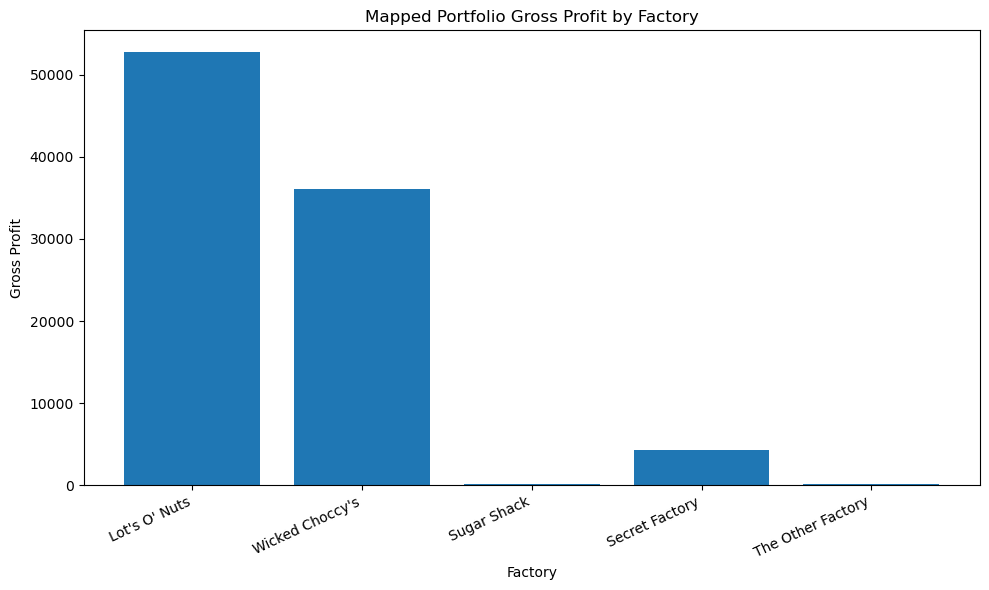

Saved: C:\Users\hp\Nassau_Candy_Final_Submission\reports\figures\factory_gross_profit.png


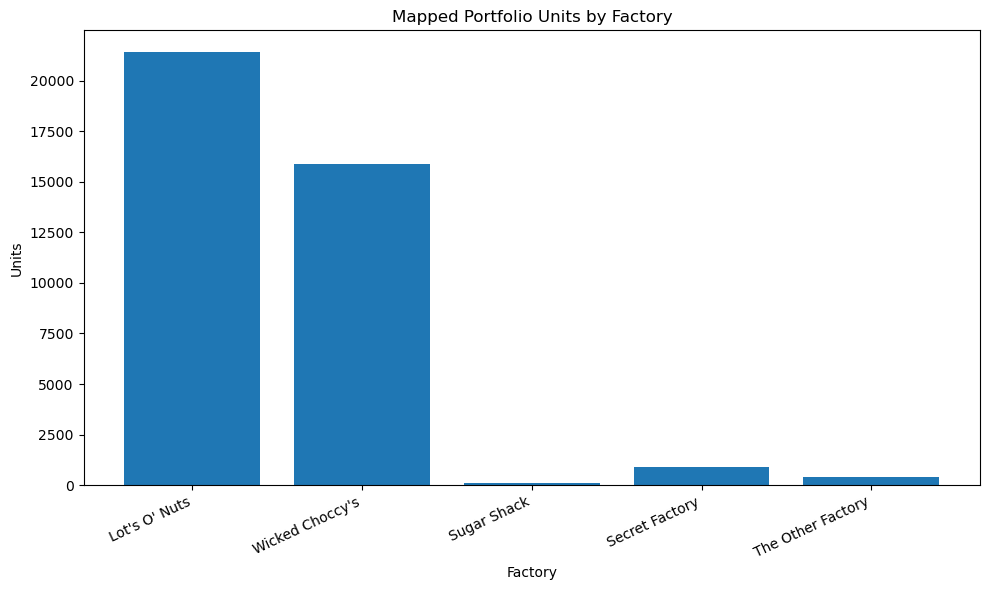

Saved: C:\Users\hp\Nassau_Candy_Final_Submission\reports\figures\factory_units.png

SUCCESS: All four factory comparison charts created.


In [32]:
#Factory comparison charts
#Objective: Create separate charts for product count, mapped portfolio sales, gross profit, and units.
# Create factory portfolio comparison charts

# Create factory portfolio comparison charts with consistent column names

import matplotlib.pyplot as plt
import os

# Standardize factory name columns across all factory summary tables

factory_product_count = factory_product_count.rename(
    columns={
        "Factory_Name": "Factory Name",
        "Mapped Factory": "Factory Name"
    }
)

factory_sales = factory_sales.rename(
    columns={
        "Factory_Name": "Factory Name",
        "Mapped Factory": "Factory Name"
    }
)

factory_gross_profit = factory_gross_profit.rename(
    columns={
        "Factory_Name": "Factory Name",
        "Mapped Factory": "Factory Name"
    }
)

factory_units = factory_units.rename(
    columns={
        "Factory_Name": "Factory Name",
        "Mapped Factory": "Factory Name"
    }
)

# Verify standardized columns
print("Product Count Columns:", factory_product_count.columns.tolist())
print("Sales Columns:", factory_sales.columns.tolist())
print("Gross Profit Columns:", factory_gross_profit.columns.tolist())
print("Units Columns:", factory_units.columns.tolist())

assert "Factory Name" in factory_product_count.columns
assert "Factory Name" in factory_sales.columns
assert "Factory Name" in factory_gross_profit.columns
assert "Factory Name" in factory_units.columns

print("\nSUCCESS: Factory column names standardized.")
# Prepare chart data
chart_data = [
    (
        factory_product_count,
        "Distinct Product Count",
        "Distinct Products by Factory",
        "Products",
        "factory_product_count.png"
    ),
    (
        factory_sales,
        "Mapped Portfolio Sales",
        "Mapped Portfolio Sales by Factory",
        "Sales",
        "factory_sales.png"
    ),
    (
        factory_gross_profit,
        "Mapped Portfolio Gross Profit",
        "Mapped Portfolio Gross Profit by Factory",
        "Gross Profit",
        "factory_gross_profit.png"
    ),
    (
        factory_units,
        "Mapped Portfolio Units",
        "Mapped Portfolio Units by Factory",
        "Units",
        "factory_units.png"
    )
]

# Generate and save charts
for data, y_col, title, y_label, filename in chart_data:

    if "Factory Name" not in data.columns:
        raise KeyError(
            f"Factory Name column missing. Available columns: {data.columns.tolist()}"
        )

    plt.figure(figsize=(10, 6))

    plt.bar(data["Factory Name"], data[y_col])

    plt.title(title)
    plt.xlabel("Factory")
    plt.ylabel(y_label)
    plt.xticks(rotation=25, ha="right")

    plt.tight_layout()

    output_path = os.path.join(FIGURES_DIR, filename)

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("Saved:", output_path)

print("\nSUCCESS: All four factory comparison charts created.")

In [38]:
#Factory analysis limitations and integrity
#Objective: Document what the reference analysis can and cannot establish, and verify that the original CSV remains unchanged.
# Document factory analysis limitations and verify original data integrity

# Document factory analysis limitations and verify original data integrity

limitations = """
FACTORY REFERENCE ANALYSIS — EVIDENCE AND LIMITATIONS

1. Factory names, coordinates, and product-to-factory assignments
   come from the supplied project reference workbook.

2. The original CSV does not contain a verified historical factory
   assignment for each order line.

3. Factory-wise sales, gross profit, and units are attributed to factories
   using the supplied product mapping. They are not verified factory-level
   production, dispatch, or financial records.

4. The analysis does not establish which factory physically manufactured
   or shipped a specific historical order.

5. Factory distances are straight-line geographic estimates calculated
   from supplied coordinates using the Haversine formula.

6. These distances are not road distances, actual transport routes,
   delivery distances, or travel times.

7. The supplied data does not establish customer coordinates, actual
   factory dispatch history, factory capacity, inventory, throughput,
   freight costs, or factory-specific manufacturing costs.

8. The analysis does not prove that assigning products to another factory
   would reduce lead time, cost, or delivery risk.

9. Any future reassignment or alternative-factory scenario must be
   labelled hypothetical unless supported by operational evidence.

10. The original CSV is preserved. Factory reference information is
    added only to separate derived files.
"""

LIMITATIONS_FILE = os.path.join(
    PROCESSED_DIR, "factory_analysis_limitations.txt"
)

with open(LIMITATIONS_FILE, "w", encoding="utf-8") as file:
    file.write(limitations.strip())

# Verify original source file integrity
original_sha256_after = calculate_sha256(RAW_FILE)

# Verify original columns and values in the mapped copy
original_values_unchanged = df_factory_mapped[
    df_original.columns
].equals(df_original)

# Verify mapping coverage
all_products_mapped = (
    df_factory_mapped["Mapped Factory"].notna().all()
)

mapped_product_count = (
    df_factory_mapped["Product Name"].nunique()
)

integrity_checks = pd.DataFrame([
    {
        "Check": "Original CSV exists",
        "Result": os.path.exists(RAW_FILE)
    },
    {
        "Check": "Original row count preserved",
        "Result": len(df_original) == 10194
    },
    {
        "Check": "Original 18 columns retained",
        "Result": len(df_original.columns) == 18
    },
    {
        "Check": "All original columns retained in mapped copy",
        "Result": all(
            col in df_factory_mapped.columns
            for col in df_original.columns
        )
    },
    {
        "Check": "Mapped copy row count preserved",
        "Result": len(df_factory_mapped) == len(df_original)
    },
    {
        "Check": "Original values unchanged in mapped copy",
        "Result": original_values_unchanged
    },
    {
        "Check": "All products mapped",
        "Result": all_products_mapped
    },
    {
        "Check": "All 15 products represented",
        "Result": mapped_product_count == 15
    },
    {
        "Check": "Original CSV hash unchanged",
        "Result": original_sha256_before == original_sha256_after
    },
    {
        "Check": "Factory master file exists",
        "Result": os.path.exists(FACTORY_MASTER_FILE)
    },
    {
        "Check": "Factory coordinates file exists",
        "Result": os.path.exists(FACTORY_COORDINATES_FILE)
    },
    {
        "Check": "Product mapping file exists",
        "Result": os.path.exists(PRODUCT_MAPPING_FILE)
    },
    {
        "Check": "Factory mapped dataset exists",
        "Result": os.path.exists(FACTORY_MAPPED_FILE)
    },
    {
        "Check": "Factory distance matrix exists",
        "Result": os.path.exists(FACTORY_DISTANCE_FILE)
    },
    {
        "Check": "Limitations report exists",
        "Result": os.path.exists(LIMITATIONS_FILE)
    }
])

display(integrity_checks)

passed_checks = integrity_checks["Result"].sum()
total_checks = len(integrity_checks)

print(f"\nIntegrity checks passed: {passed_checks}/{total_checks}")
print("All integrity checks passed:",
      integrity_checks["Result"].all())

print("\nOriginal CSV SHA-256 before:", original_sha256_before)
print("Original CSV SHA-256 after: ", original_sha256_after)

assert integrity_checks["Result"].all(), (
    "One or more integrity checks failed. Review the table above."
)

print("\nSUCCESS: factory reference analysis completed.")

,Check,Result
0,Original CSV exists,True
1,Original row count preserved,True
2,Original 18 columns retained,True
3,All original columns retained in mapped copy,True
4,Mapped copy row count preserved,True
5,Original values unchanged in mapped copy,True
6,All products mapped,True
7,All 15 products represented,True
8,Original CSV hash unchanged,True
9,Factory master file exists,True



Integrity checks passed: 15/15
All integrity checks passed: True

Original CSV SHA-256 before: 6ae9208e77ce410e90073b19813d29f89853ce9f3cce43d41f9643781696e94f
Original CSV SHA-256 after:  6ae9208e77ce410e90073b19813d29f89853ce9f3cce43d41f9643781696e94f

SUCCESS: factory reference analysis completed.
